# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import AustinZoningDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/austin_zoning/",
    "csv_file": "./data/austin_zoning/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = AustinZoningDataset(dataset_config)

## Show images from the dataset

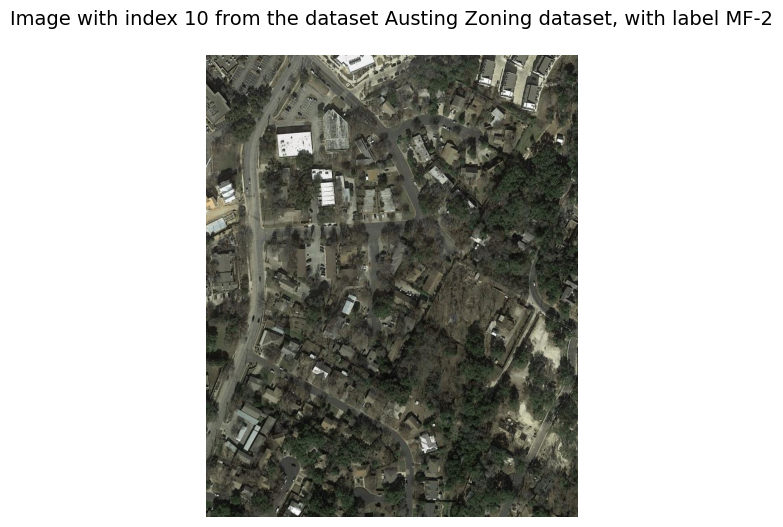

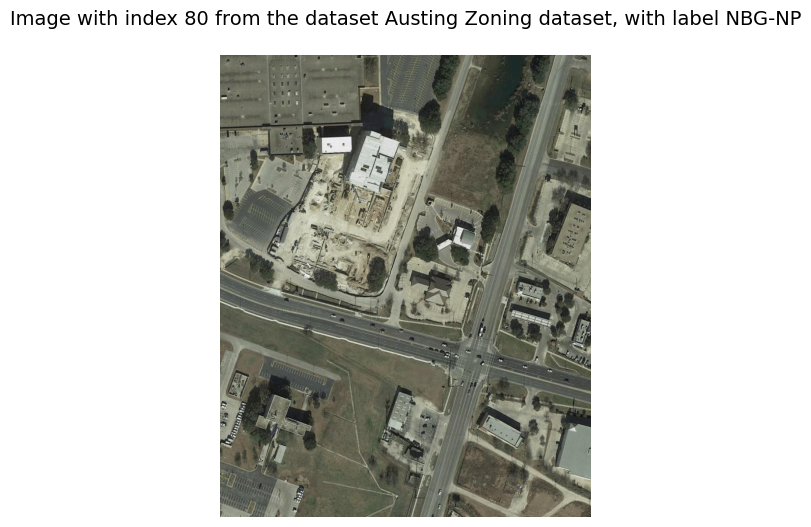

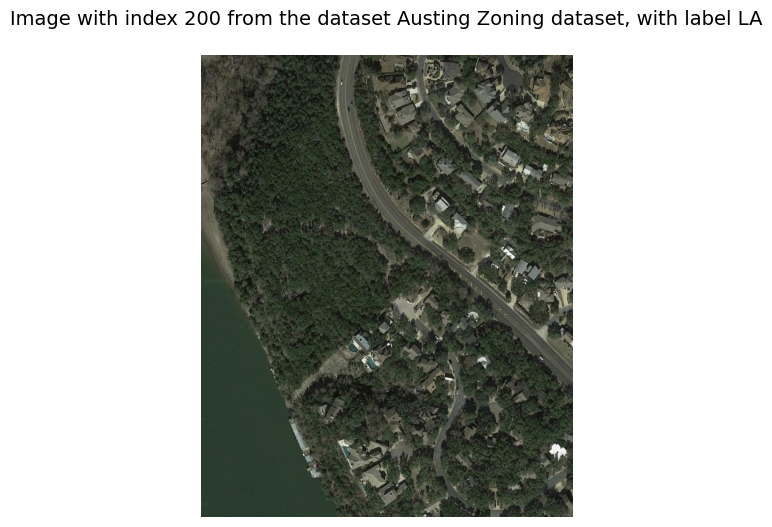

In [5]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

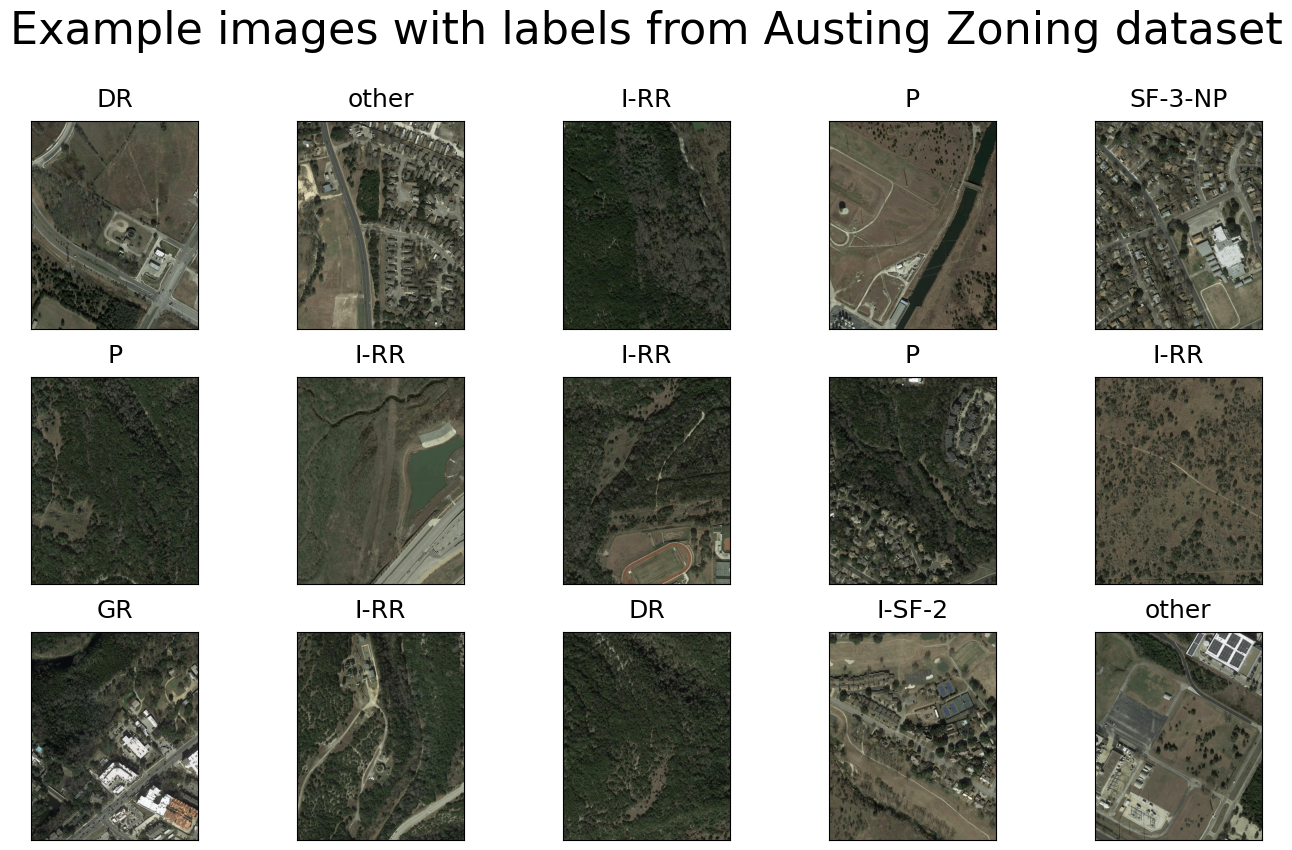

In [6]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [7]:
dataset.show_samples()

,File name,Label
0,data/austin_1113.jpg,PUD-NP
1,data/austin_1520.jpg,LI-PDA-NP
2,data/austin_3604.jpg,PUD
3,data/austin_3561.jpg,CH
4,data/austin_52.jpg,CR-CO
5,data/austin_1701.jpg,P
6,data/austin_2666.jpg,SF-3
7,data/austin_2372.jpg,LA
8,data/austin_3339.jpg,PUD
9,data/austin_1599.jpg,P


In [8]:
dataset.data_distribution_table()

,Label,Count
0,AG,8
1,AG-NP,3
2,AV,71
3,CBD,4
4,CH,2
...,...,...
148,SF-6-NP,9
149,TOD-CURE-NP,1
150,TOD-NP-CO,1
151,UNZ,28


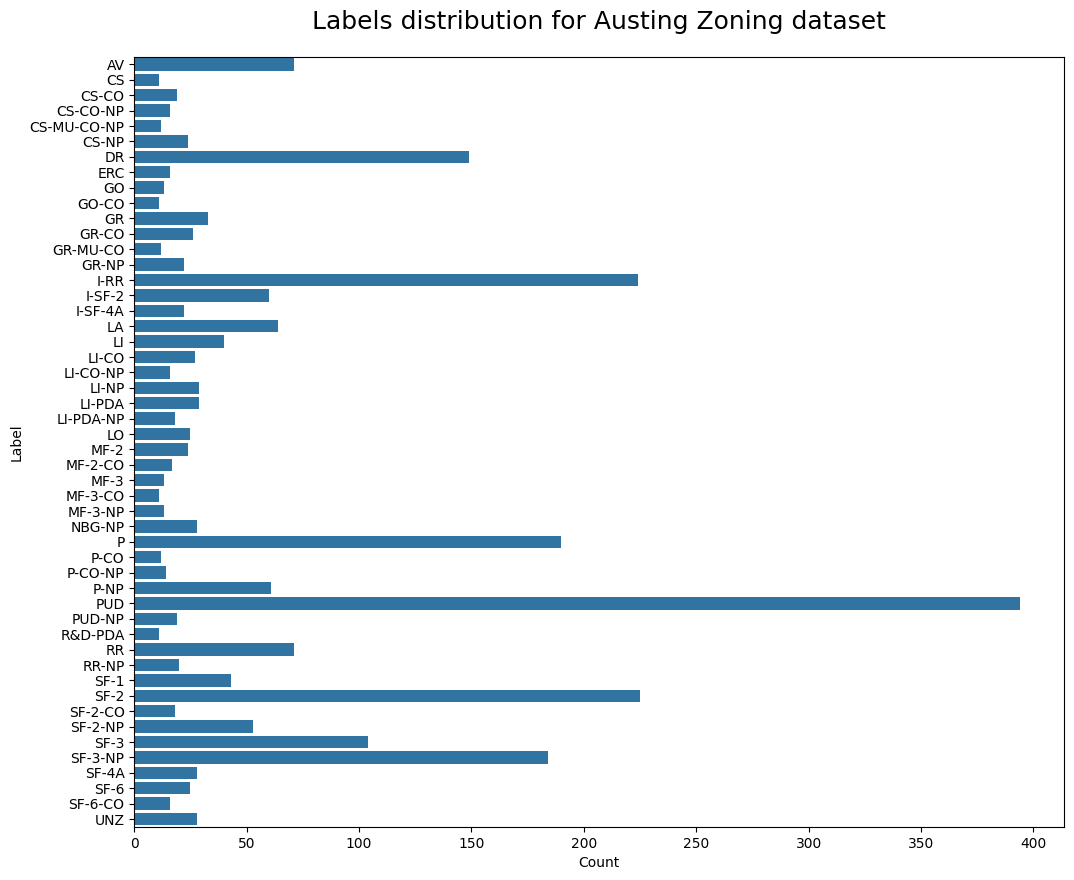

In [29]:
fig = dataset.data_distribution_barchart() #plot the majority classes

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/austin_zoning/",
    "csv_file": "./data/austin_zoning/train.csv",
}

train_dataset = AustinZoningDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/austin_zoning/",
    "csv_file": "./data/austin_zoning/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = AustinZoningDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(2935, 366)

## Setup and create the model for training

In [ ]:
epochs = 20
model_directory = "./data/experiments/austin_zoning/"
model_config = {
    "num_classes": 51, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-20 07:17:22,436 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-20 07:17:22,614 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [11]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-20 07:17:24,796 INFO Starting training.
training: 100%|██████████| 92/92 [00:24<00:00,  3.68it/s]
2025-05-20 07:17:49,903 INFO epoch: 1, time: 25, loss:  3.11948
testing on train set: 100%|██████████| 92/92 [00:08<00:00, 10.62it/s]
2025-05-20 07:18:00,806 INFO Accuracy:0.3114139693356048, Precision Micro:0.3114139693356048, Precision Macro:0.1167074552450242, Precision Weighted:0.2741610893983856, Precision per Class:[0.6875     0.         0.         0.         0.         0.
 0.359375   0.         0.         0.         0.         0.
 0.         0.         0.37888199 0.         0.         0.75
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.26495726 0.         0.         0.28571429 0.4622824
 0.         0.         0.5        0.         0.         0.26691729
 0.         0.         0.18095238 0.62195122 0.         0.
 0.         1.         0.19354839], Recall Micro:0.3114139693356048, Recall Macro:

0.10315280371969106

## Test the model

In [ ]:

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/austin_zoning/",
    "csv_file": "./data/austin_zoning/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = AustinZoningDataset(test_dataset_config)
model_path = "./data/experiments/austin_zoning/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-20 07:37:58,288 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/austin_zoning/checkpoint.pth.tar
2025-05-20 07:37:58,596 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/austin_zoning/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 23/23 [00:01<00:00, 14.29it/s]


[{'Accuracy': 0.4344262295081967},
 {'Precision Micro': 0.4344262295081967,
  'Precision Macro': 0.2132182584762979,
  'Precision Weighted': 0.42663395871348464,
  'Precision per Class': array([0.77777778, 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.4       , 0.        , 0.        , 1.        ,
         1.        , 0.        , 0.        , 0.        , 0.47826087,
         0.36363636, 0.        , 0.75      , 0.33333333, 0.        ,
         0.        , 0.5       , 0.75      , 0.        , 0.25      ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.4       , 0.        , 0.        , 0.        ,
         0.63768116, 0.        , 0.        , 0.7       , 0.        ,
         0.        , 0.30952381, 0.        , 0.        , 0.25      ,
         0.55882353, 0.        , 0.        , 0.        , 1.        ,
         0.41509434])},
 {'Recall Micro': 0.4344262295081967,
  'Recall Macro': 0.18936964875469325,
  'Recall Weighted': 0.4

## Predictions

2025-05-20 07:51:03,906 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/austin_zoning/checkpoint.pth.tar
2025-05-20 07:51:04,771 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/austin_zoning/checkpoint.pth.tar at epoch 21


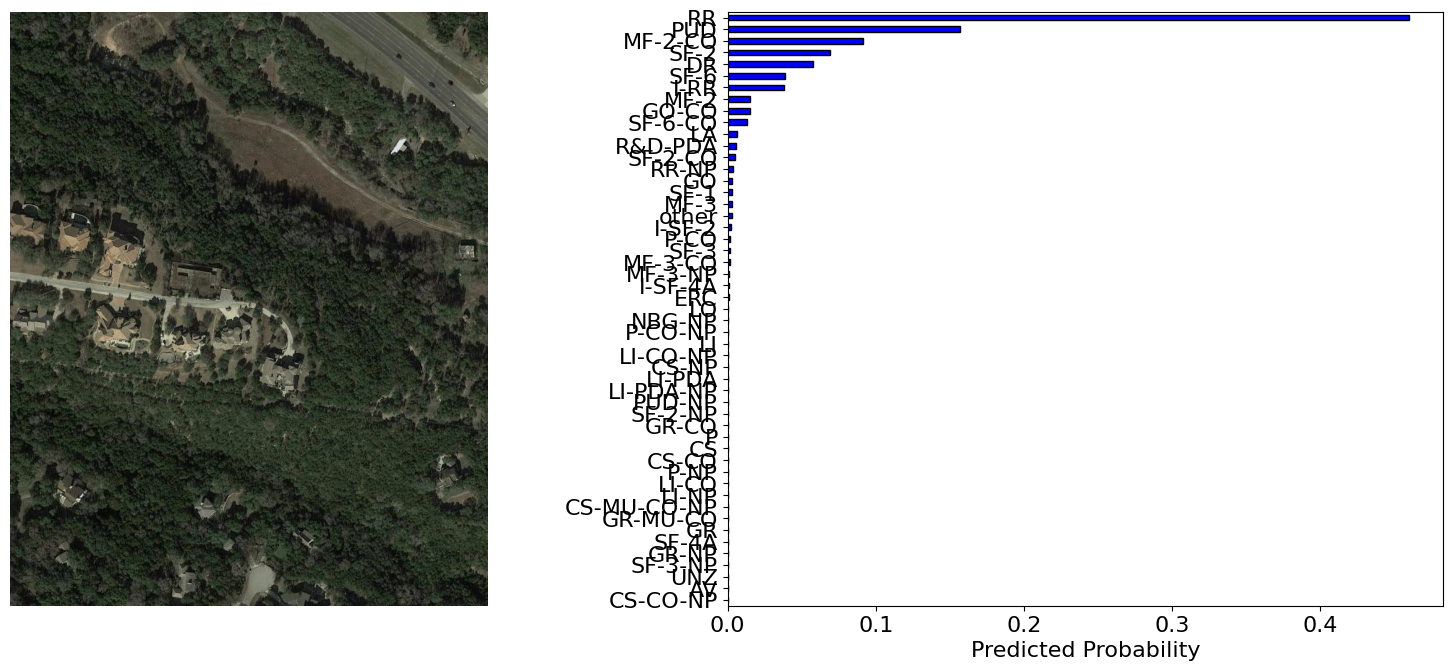

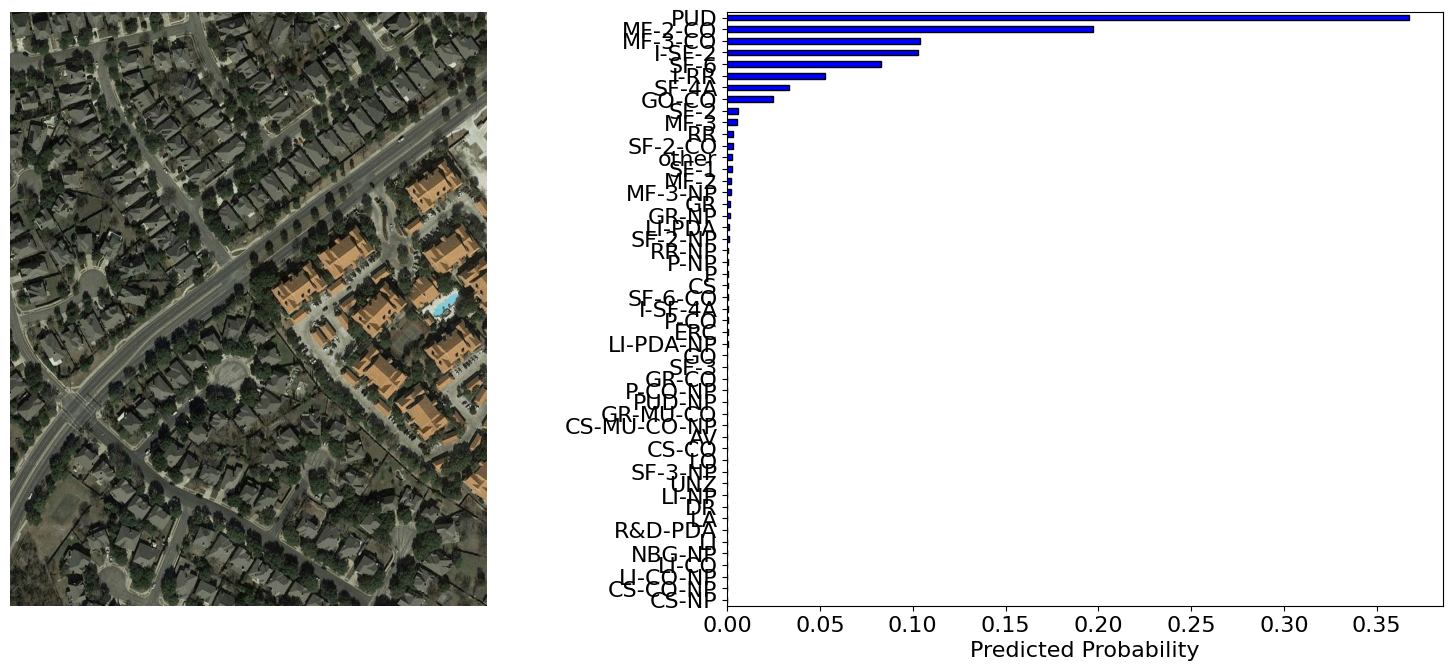

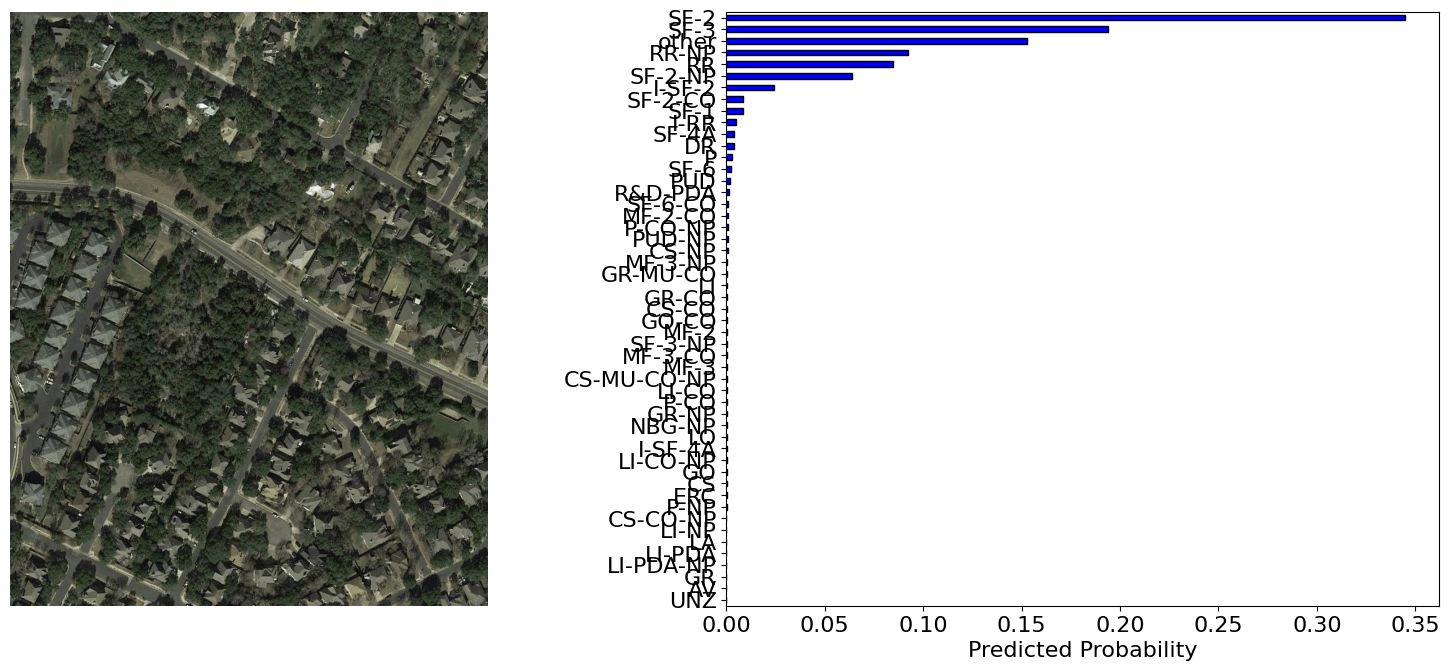

In [ ]:
labels = ["AV","CS","CS-CO","CS-CO-NP","CS-MU-CO-NP","CS-NP","DR","ERC","GO","GO-CO","GR",
              "GR-CO","GR-MU-CO","GR-NP","I-RR","I-SF-2","I-SF-4A","LA","LI","LI-CO","LI-CO-NP",
              "LI-NP","LI-PDA","LI-PDA-NP","LO","MF-2","MF-2-CO","MF-3","MF-3-CO","MF-3-NP","NBG-NP",
              "P","P-CO","P-CO-NP","P-NP","PUD","PUD-NP","R&D-PDA","RR","RR-NP","SF-1","SF-2","SF-2-CO",
              "SF-2-NP","SF-3","SF-3-NP","SF-4A","SF-6","SF-6-CO","UNZ","other"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/austin_zoning/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/austin_zoning/data/austin_2735.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/austin_zoning/data/austin_3208.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/austin_zoning/data/austin_1064.jpg')
fig = model.predict_image(image, labels, transform)